# Imports and Mounting


In [ ]:
# Import pandas and scikit
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
import xgboost as xgb
from sklearn.neural_network import MLPRegressor


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load dataset
path = "/content/drive/MyDrive/final_life_pm25.csv"
df = pd.read_csv(path)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (2500, 17)


,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,hepatitis_b,measles,polio,diphtheria,hiv/aids,gdp,population,schooling,pm25,country_encoded,population_log
0,2000,0,54.8,321.0,88.0,0.01,62.0,6532.0,24.0,24.0,0.1,114.560000,293756.0,5.5,64.767280,0,12.590508
1,2001,0,55.3,316.0,88.0,0.01,63.0,8762.0,35.0,33.0,0.1,117.496980,2966463.0,5.9,64.597573,0,14.902881
2,2002,0,56.2,3.0,88.0,0.01,64.0,2486.0,36.0,36.0,0.1,187.845950,21979923.0,6.2,64.416888,0,16.905640
3,2003,0,56.7,295.0,87.0,0.01,65.0,798.0,41.0,41.0,0.1,198.728544,2364851.0,6.5,64.176231,0,14.676226
4,2004,0,57.0,293.0,87.0,0.02,67.0,466.0,5.0,5.0,0.1,219.141353,24118979.0,6.8,63.826609,0,16.998510


# Dataset pre-processing

In [ ]:
import pandas as pd
import csv

# --- 1. Read Life Expectancy dataset ---
life_expectancy = pd.read_csv("/content/drive/MyDrive/Life Expectancy Data.csv")
life_expectancy.columns = life_expectancy.columns.str.strip().str.lower()

# Make sure 'country' and 'year' exist
print("Life Expectancy columns:", life_expectancy.columns.tolist())

# --- 2. Read PM2.5 dataset ---
with open("/content/drive/MyDrive/API_EN.ATM.PM25.MC.M3_DS2_en_csv_v2_3016.csv", "r") as f:
    first_line = f.readline()
    sniffer = csv.Sniffer()
    dialect = sniffer.sniff(first_line)
    delimiter = dialect.delimiter
    print(f"Detected delimiter: '{delimiter}'")

pm25 = pd.read_csv("/content/drive/MyDrive/API_EN.ATM.PM25.MC.M3_DS2_en_csv_v2_3016.csv", sep=delimiter, skiprows=4)
pm25.columns = pm25.columns.str.strip().str.lower()

# --- 3. Detect and rename 'country' column ---
country_col = None
for col in pm25.columns:
    if 'country' in col.lower():
        country_col = col
        break
if country_col is None:
    raise ValueError("No column corresponding to 'country' found in PM2.5 dataset!")
else:
    pm25 = pm25.rename(columns={country_col: 'country'})

# --- 4. Reshape PM2.5 dataset from wide → long format ---
year_cols = [col for col in pm25.columns if col != 'country']
pm25_long = pm25.melt(id_vars='country', value_vars=year_cols,
                      var_name='year', value_name='pm25')

# Convert year to numeric
pm25_long['year'] = pd.to_numeric(pm25_long['year'], errors='coerce')

# Drop rows with missing PM2.5 or year
pm25_long = pm25_long.dropna(subset=['year', 'pm25'])

# --- 5. Merge life expectancy with PM2.5 by country and year ---
merged_df = pd.merge(
    life_expectancy,
    pm25_long,
    on=['country', 'year'],
    how='inner'
)

# --- 6. Optional: merge additional indicators ---
# Example: GDP dataset (replace with your path)
# gdp = pd.read_csv("/content/drive/MyDrive/gdp.csv")
# gdp.columns = gdp.columns.str.strip().str.lower()
# merged_df = pd.merge(merged_df, gdp, on=['country','year'], how='left')

# --- 7. Inspect final dataset ---
print(merged_df.head())
print(f"Merged dataset shape: {merged_df.shape}")


Life Expectancy columns: ['country', 'year', 'status', 'life expectancy', 'adult mortality', 'infant deaths', 'alcohol', 'percentage expenditure', 'hepatitis b', 'measles', 'bmi', 'under-five deaths', 'polio', 'total expenditure', 'diphtheria', 'hiv/aids', 'gdp', 'population', 'thinness  1-19 years', 'thinness 5-9 years', 'income composition of resources', 'schooling']
Detected delimiter: ','
       country  year      status  life expectancy  adult mortality  \
0  Afghanistan  2015  Developing             65.0            263.0   
1  Afghanistan  2014  Developing             59.9            271.0   
2  Afghanistan  2013  Developing             59.9            268.0   
3  Afghanistan  2012  Developing             59.5            272.0   
4  Afghanistan  2011  Developing             59.2            275.0   

   infant deaths  alcohol  percentage expenditure  hepatitis b  measles  ...  \
0             62     0.01               71.279624         65.0     1154  ...   
1             64     0.

In [ ]:
# Save to Google Drive
merged_df.to_csv("/content/drive/MyDrive/merged_life_pm25.csv", index=False)
print("CSV saved to Google Drive!")


CSV saved to Google Drive!


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset Shape: (2519, 23)

First 5 Rows:


,country,year,status,life expectancy,adult mortality,infant deaths,alcohol,percentage expenditure,hepatitis b,measles,...,total expenditure,diphtheria,hiv/aids,gdp,population,thinness 1-19 years,thinness 5-9 years,income composition of resources,schooling,pm25
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1,73.490818
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0,77.143728
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9,73.131816
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8,70.922317
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5,61.817056



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2519 entries, 0 to 2518
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   country                          2519 non-null   object 
 1   year                             2519 non-null   int64  
 2   status                           2519 non-null   object 
 3   life expectancy                  2512 non-null   float64
 4   adult mortality                  2512 non-null   float64
 5   infant deaths                    2519 non-null   int64  
 6   alcohol                          2350 non-null   float64
 7   percentage expenditure           2519 non-null   float64
 8   hepatitis b                      2029 non-null   float64
 9   measles                          2519 non-null   int64  
 10  bmi                              2485 non-null   float64
 11  under-five deaths                2519 non-null   int64  
 12  polio

,year,life expectancy,adult mortality,infant deaths,alcohol,percentage expenditure,hepatitis b,measles,bmi,under-five deaths,...,total expenditure,diphtheria,hiv/aids,gdp,population,thinness 1-19 years,thinness 5-9 years,income composition of resources,schooling,pm25
count,2519.000000,2512.000000,2512.000000,2519.000000,2350.000000,2519.000000,2029.000000,2519.000000,2485.000000,2519.000000,...,2349.000000,2500.000000,2519.000000,2455.000000,2.254000e+03,2485.000000,2485.000000,2498.000000,2502.000000,2519.000000
mean,2007.515284,69.492357,161.045382,31.026995,4.611826,857.672900,80.889601,2317.150854,38.358471,43.112346,...,5.867075,82.576800,1.668360,7549.404493,1.269338e+07,4.878471,4.924386,0.629159,12.029456,28.042975
std,4.613375,9.544559,124.556208,125.834435,4.073284,2123.042044,24.912146,11012.972527,20.107298,171.083812,...,2.413039,23.421843,4.613442,14355.436178,6.134169e+07,4.560748,4.659804,0.215451,3.469732,17.037612
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,2.000000,0.000000,1.000000,0.000000,...,0.370000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000,5.405750
25%,2004.000000,63.400000,71.000000,0.000000,0.830000,20.852306,77.000000,0.000000,18.900000,0.000000,...,4.210000,79.000000,0.100000,464.207204,1.989565e+05,1.600000,1.600000,0.488000,10.100000,16.490325
50%,2008.000000,72.300000,137.500000,2.000000,3.880000,106.180706,92.000000,15.000000,43.900000,3.000000,...,5.760000,93.000000,0.100000,1768.921320,1.404827e+06,3.300000,3.300000,0.682000,12.400000,23.039774
75%,2012.000000,76.000000,224.000000,20.000000,7.600000,557.323366,96.000000,351.500000,56.300000,25.000000,...,7.510000,97.000000,0.800000,5963.011230,7.433658e+06,7.100000,7.200000,0.787000,14.400000,34.383223
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,...,17.240000,99.000000,43.500000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000,107.144665



Missing Values Count:


,0
country,0
year,0
status,0
life expectancy,7
adult mortality,7
infant deaths,0
alcohol,169
percentage expenditure,0
hepatitis b,490
measles,0


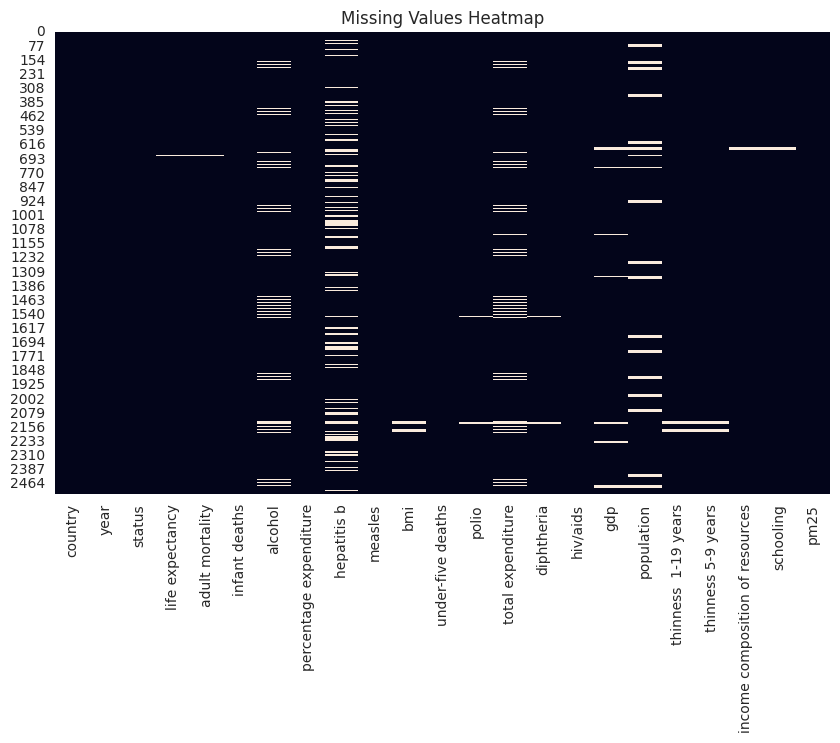


Duplicate Rows: 0


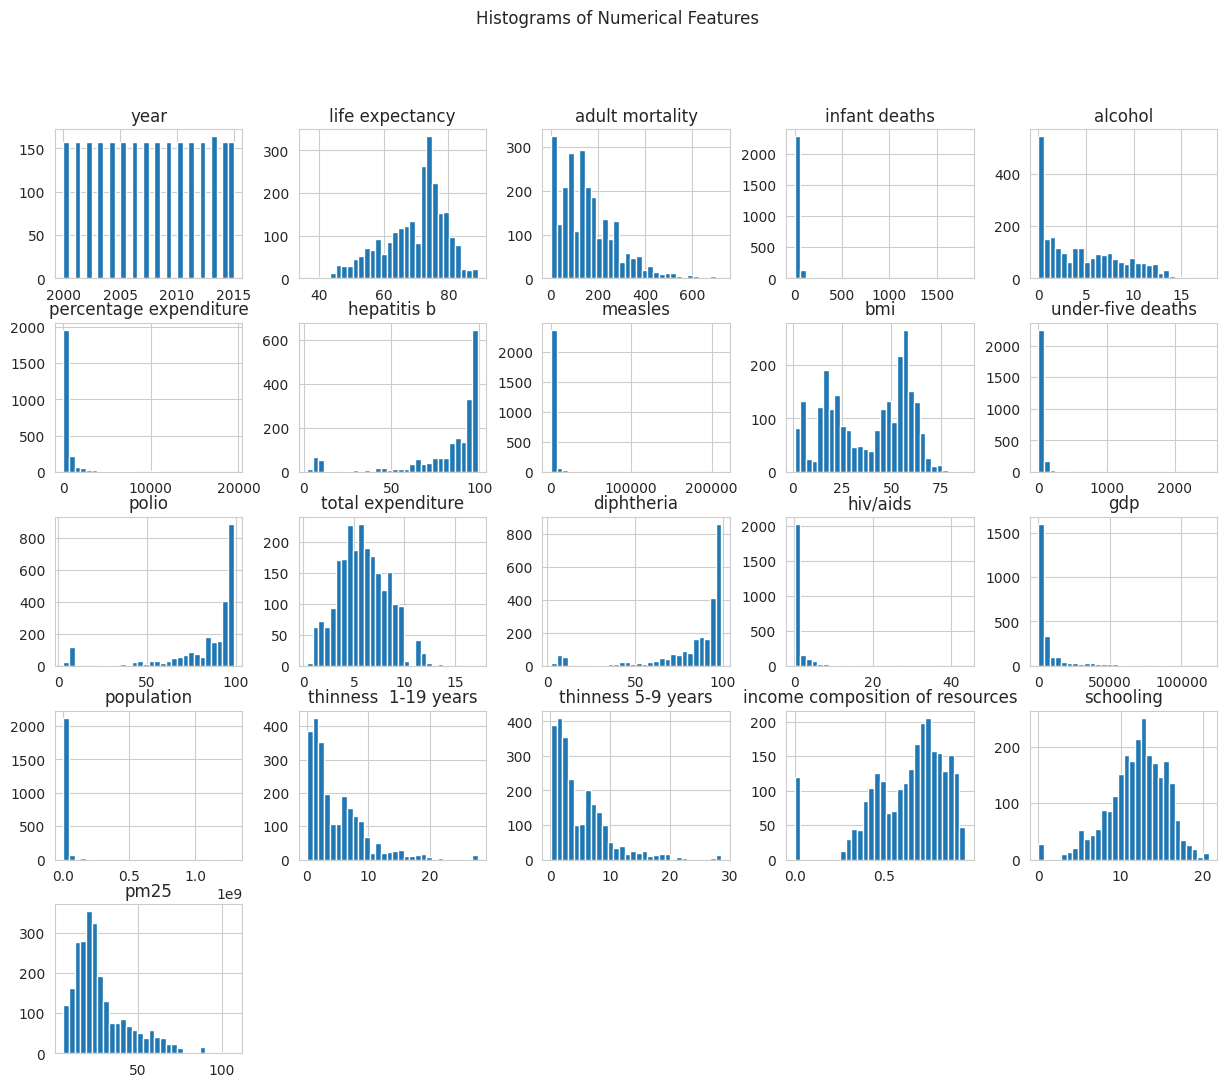

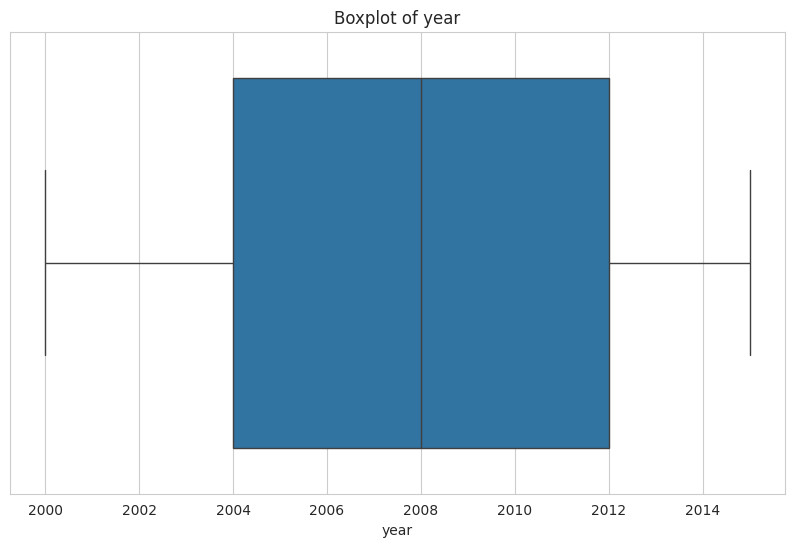

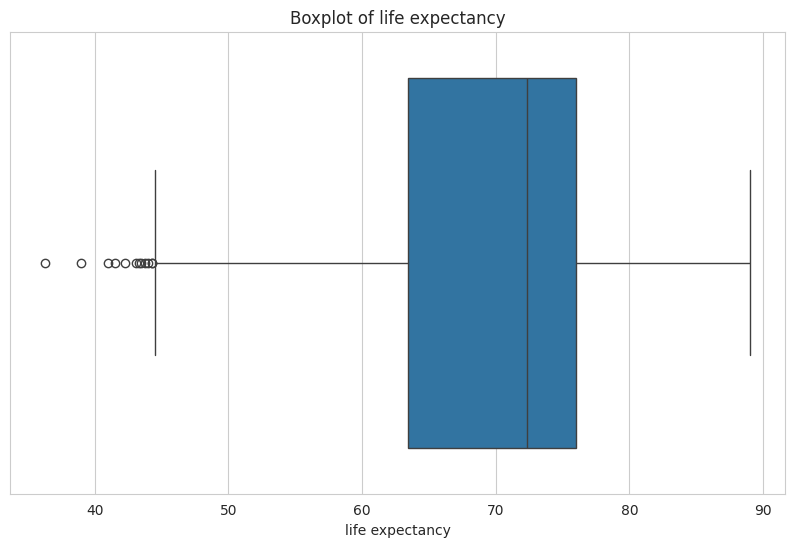

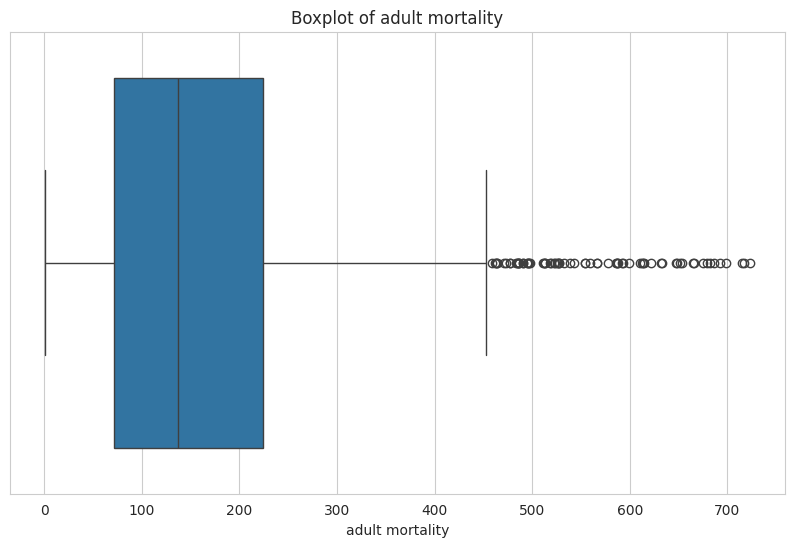

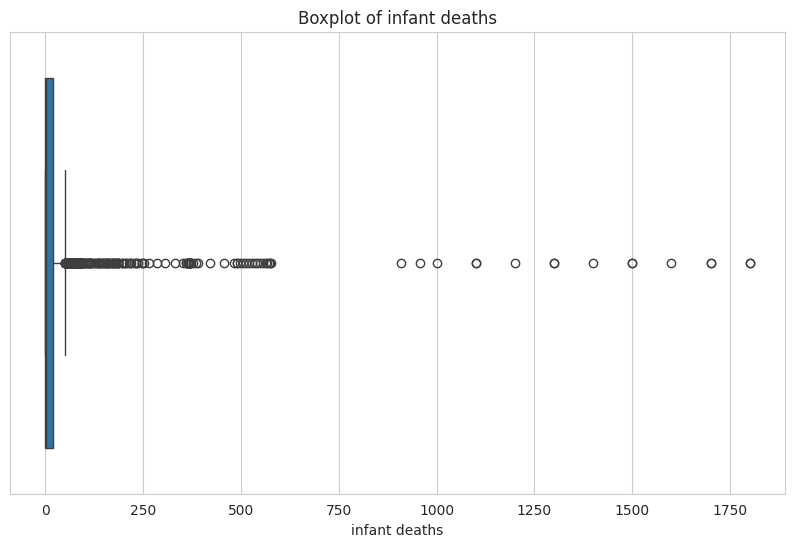

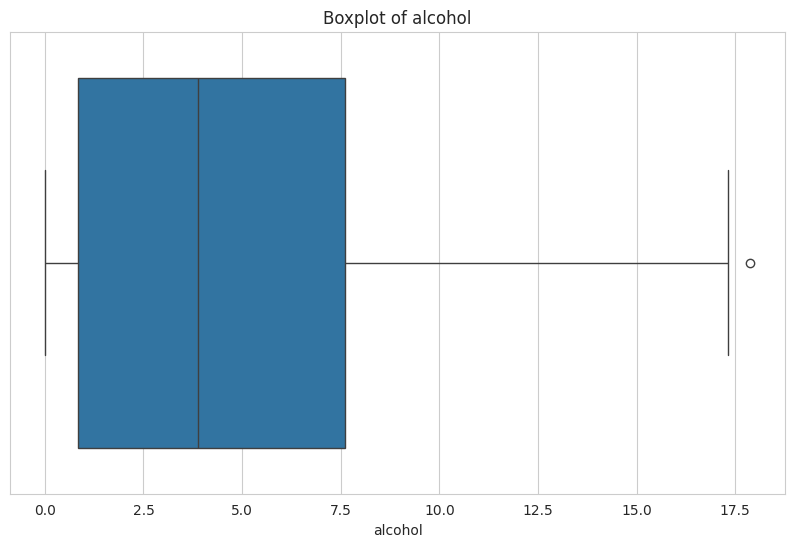

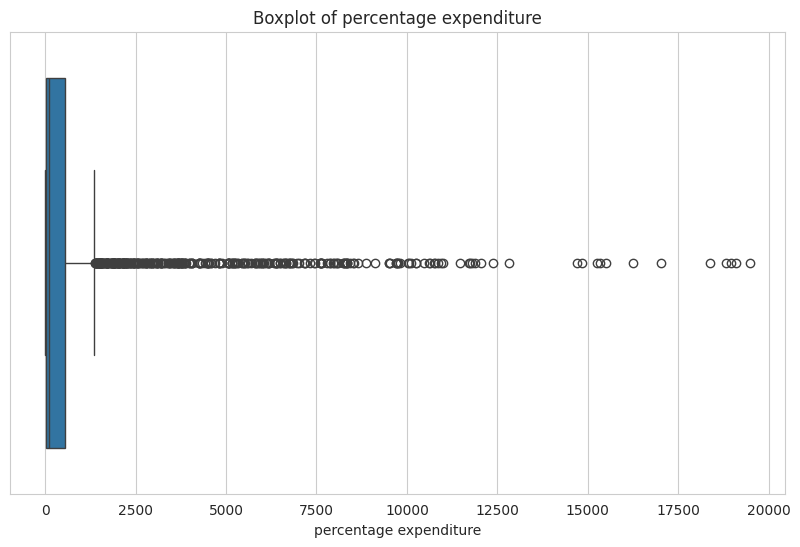

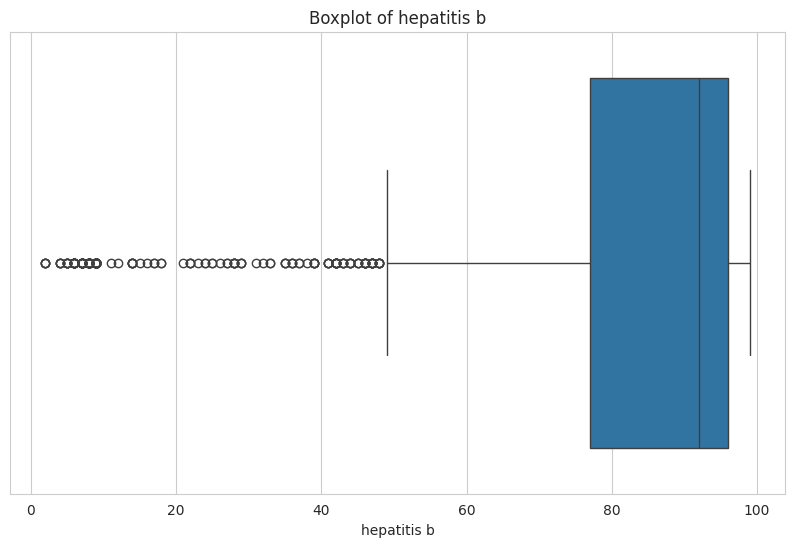

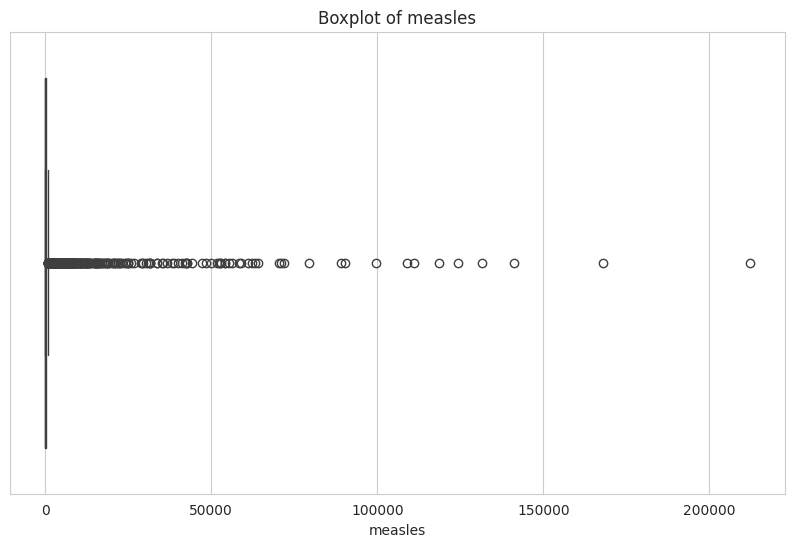

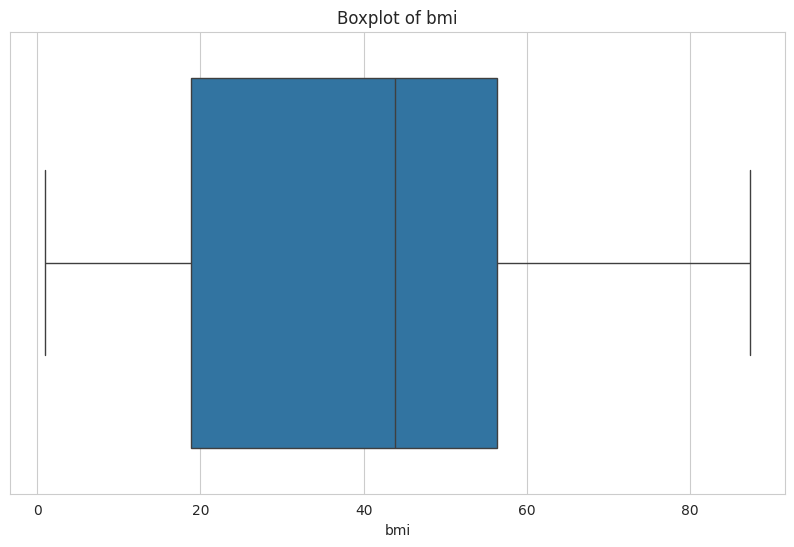

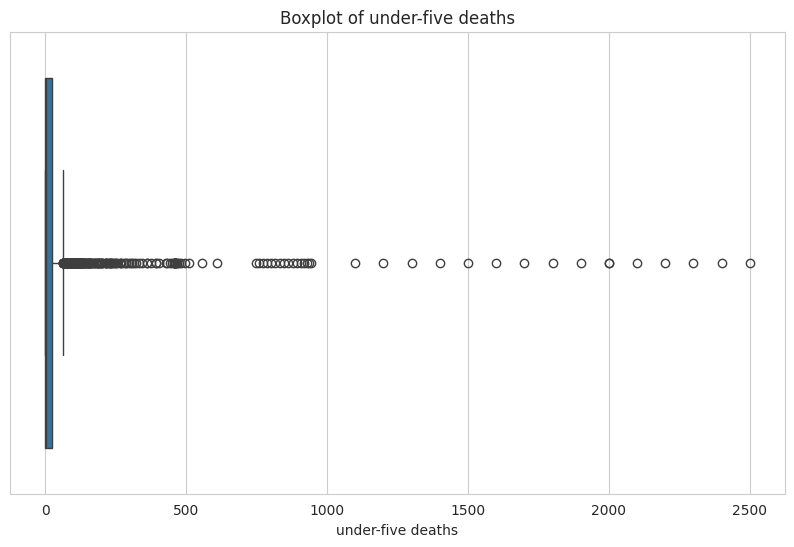

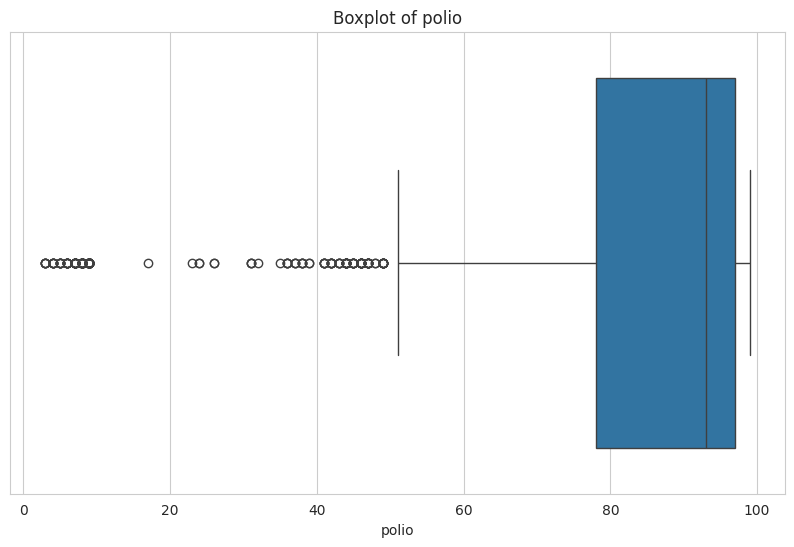

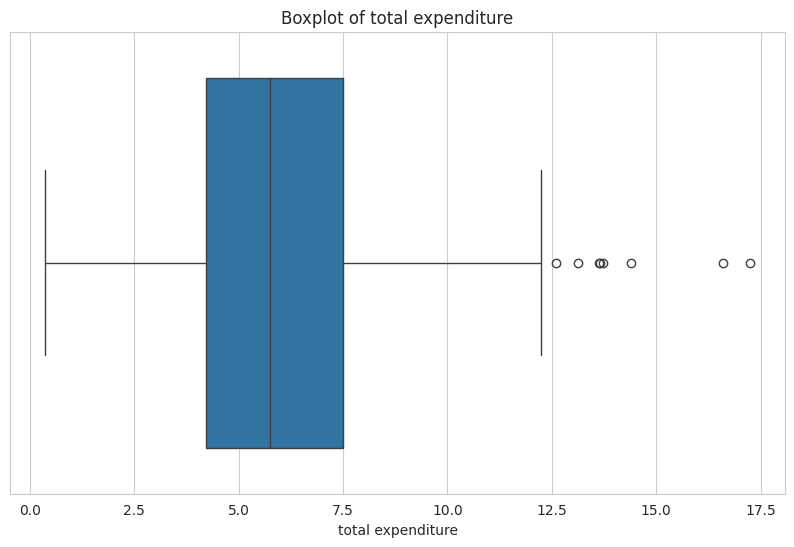

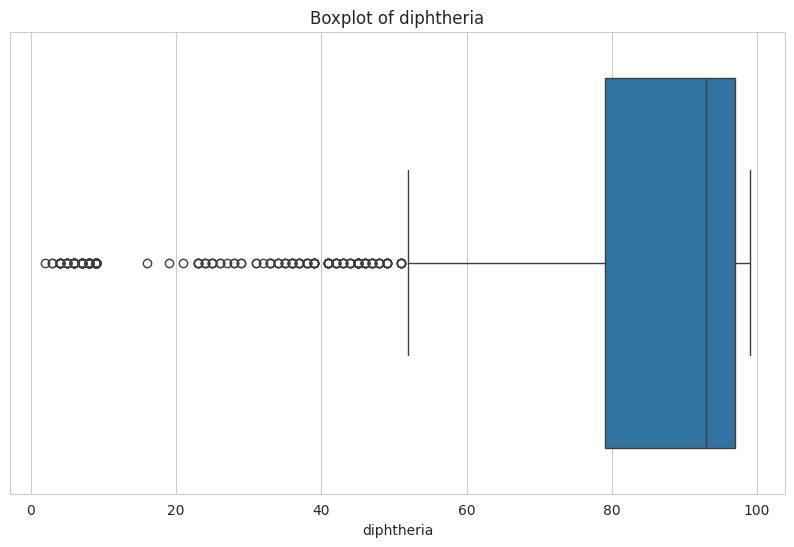

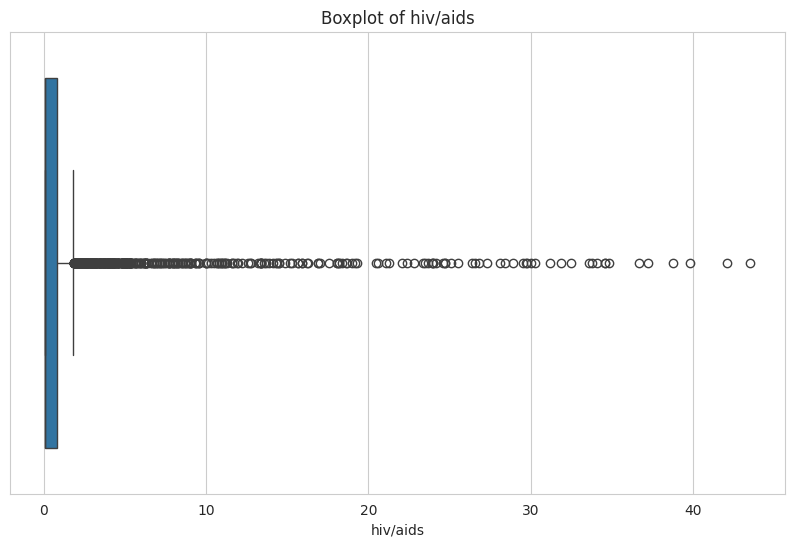

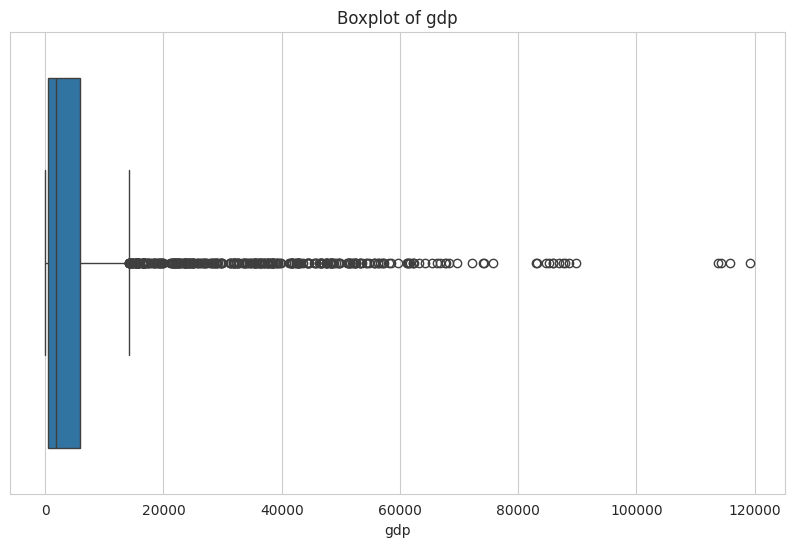

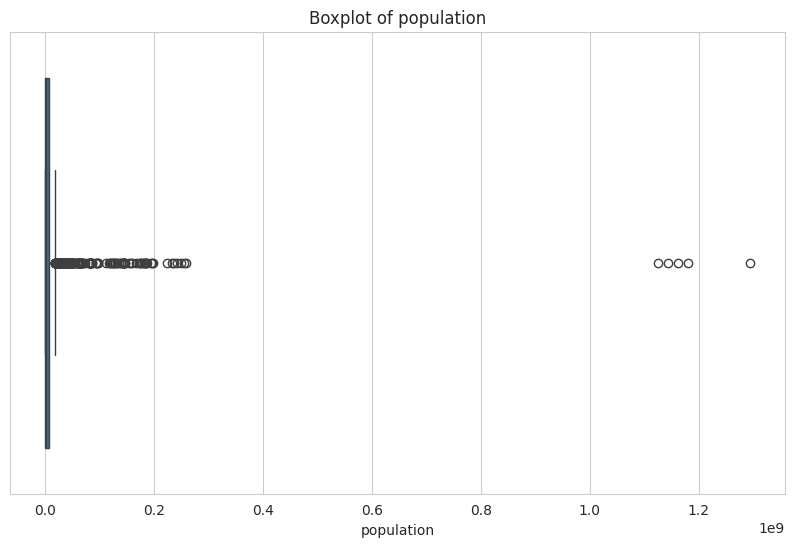

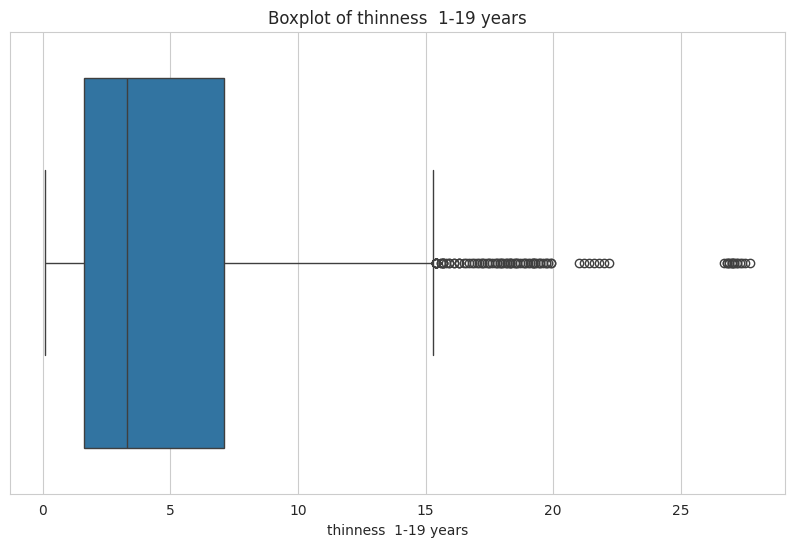

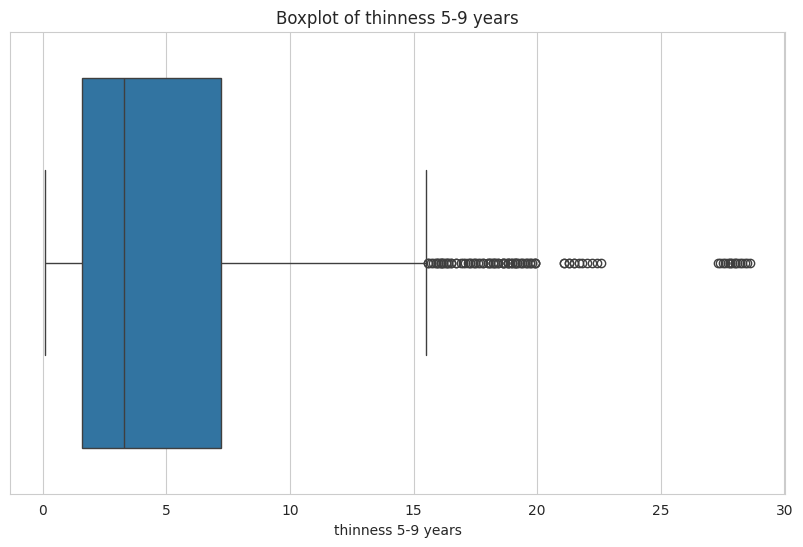

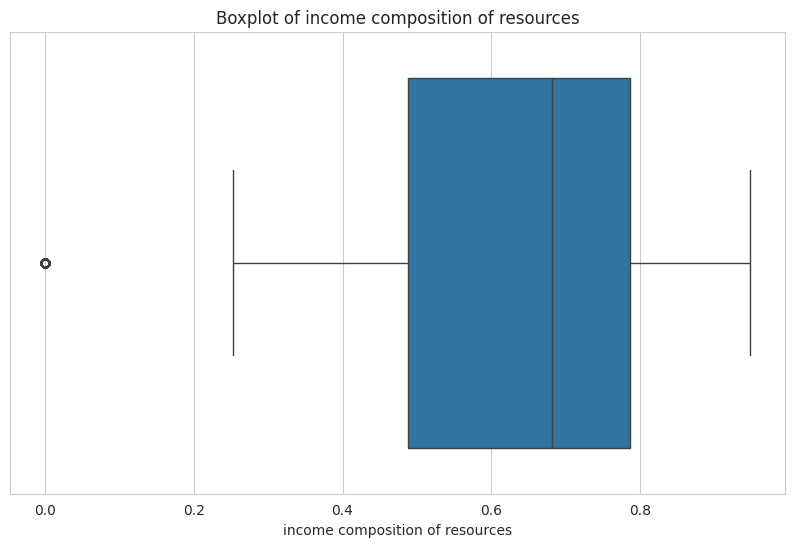

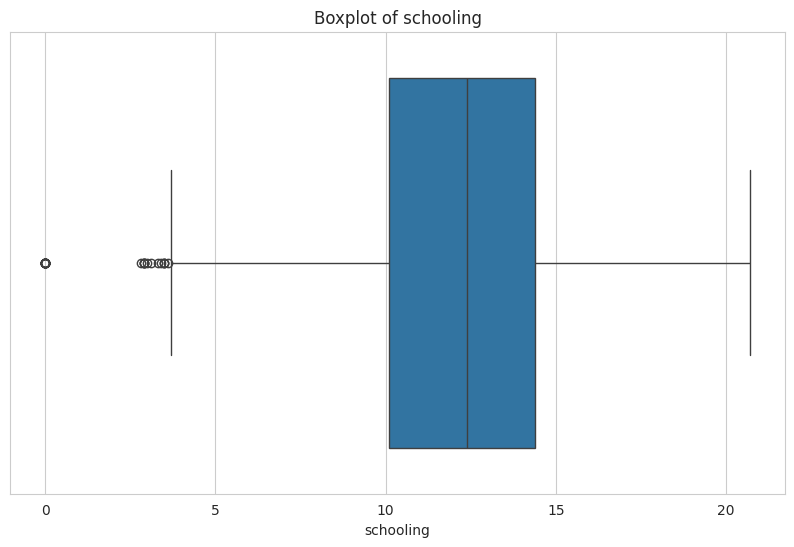

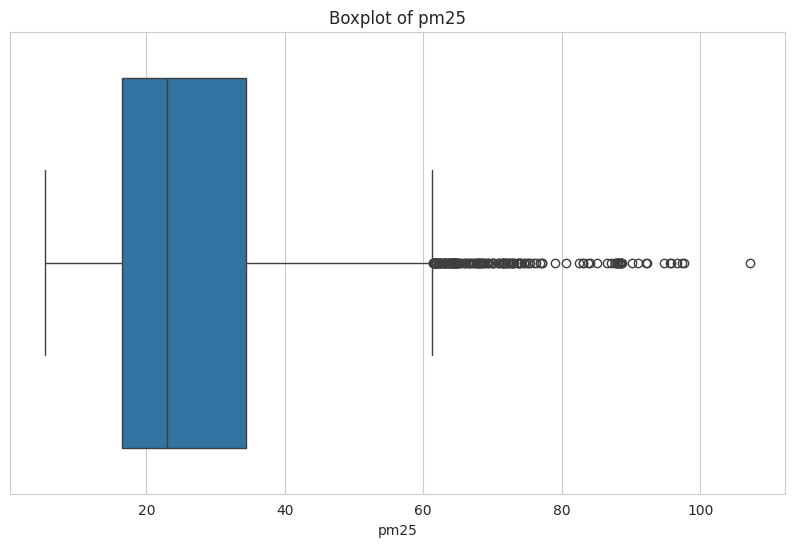

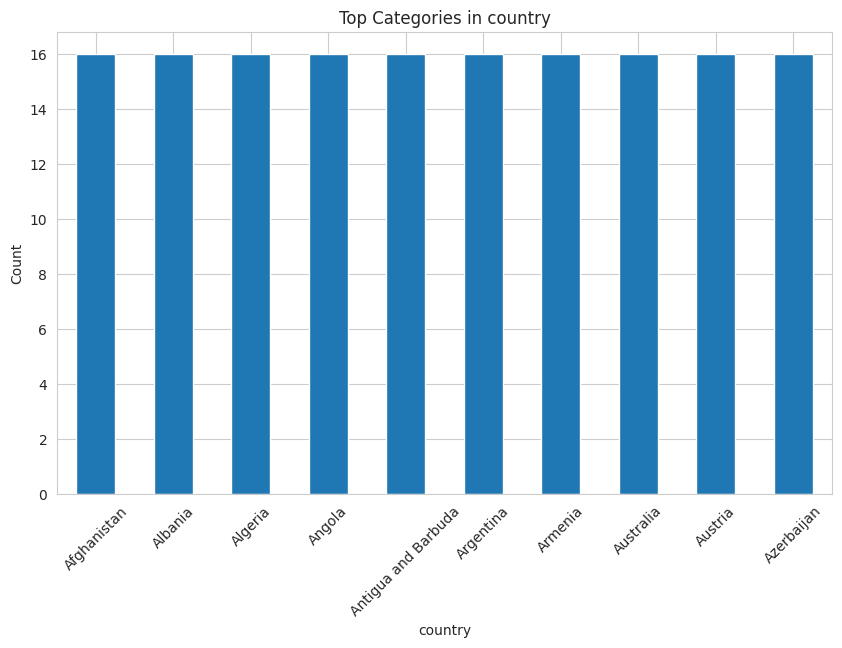

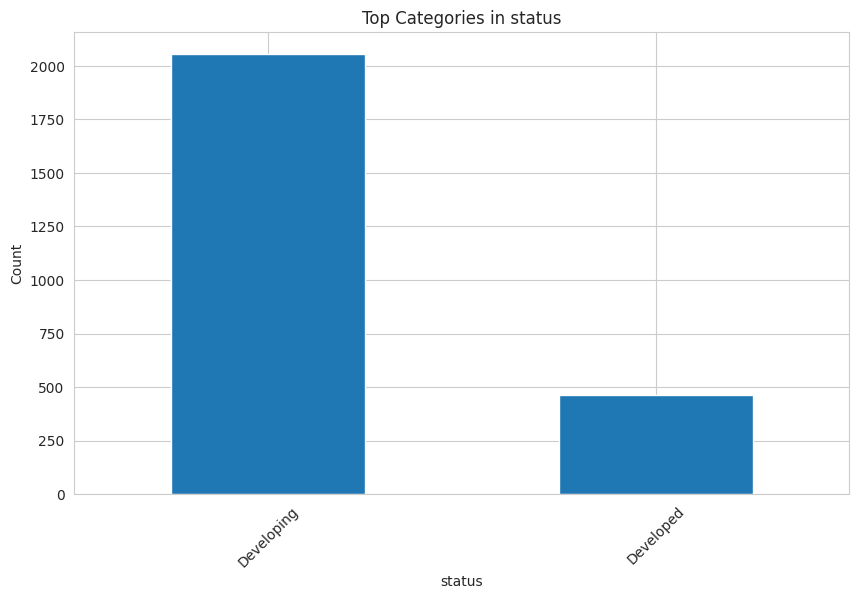

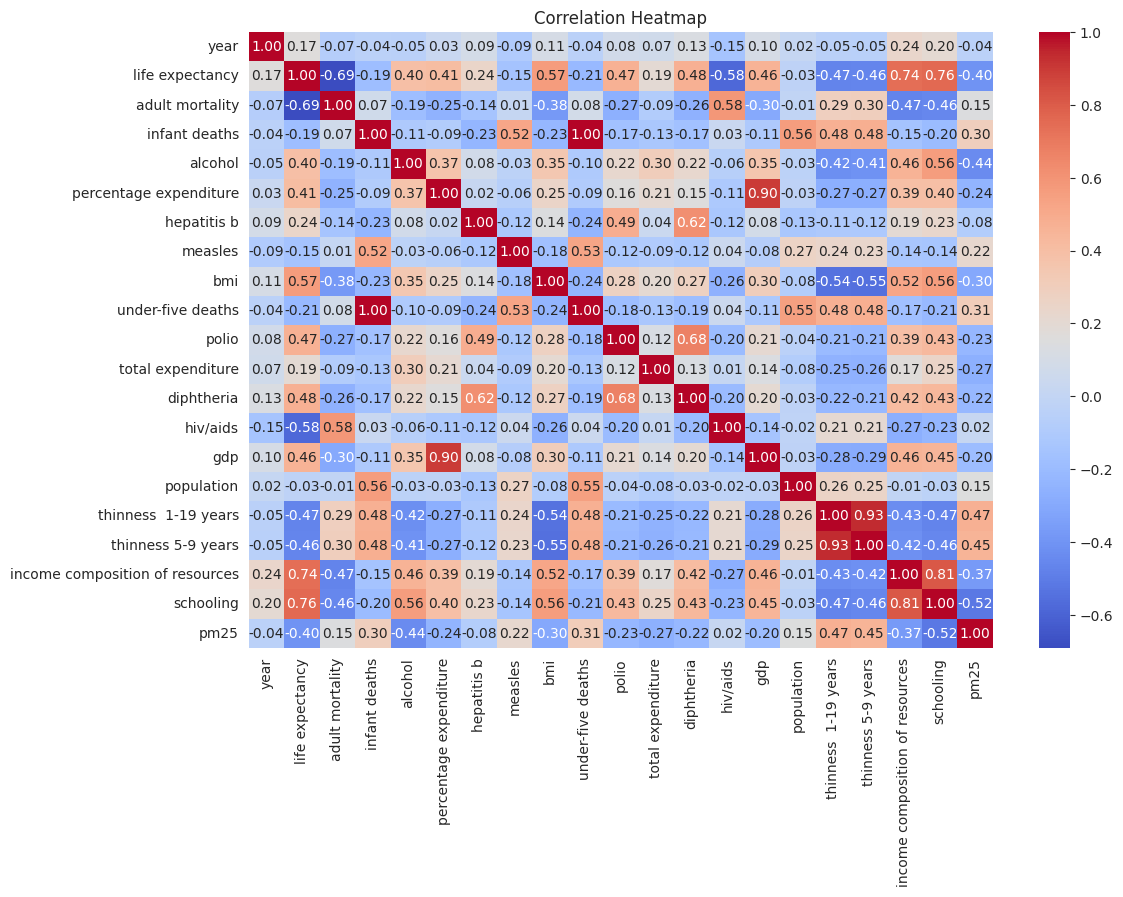


✅ Initial EDA Completed Successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

file_path = "/content/drive/MyDrive/merged_life_pm25.csv"
df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Info:")
df.info()

print("\nSummary Statistics:")
display(df.describe())

print("\nMissing Values Count:")
display(df.isnull().sum())

plt.figure()
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

print("\nDuplicate Rows:", df.duplicated().sum())

num_cols = df.select_dtypes(include=[np.number]).columns

df[num_cols].hist(bins=30, figsize=(15, 12))
plt.suptitle("Histograms of Numerical Features")
plt.show()

for col in num_cols:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


cat_cols = df.select_dtypes(include=["object"]).columns

for col in cat_cols:
    plt.figure()
    df[col].value_counts().head(10).plot(kind="bar")
    plt.title(f"Top Categories in {col}")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

plt.figure(figsize=(12, 8))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

if "PM2.5" in df.columns and "Life_Expectancy" in df.columns:
    plt.figure()
    sns.scatterplot(x=df["PM2.5"], y=df["Life_Expectancy"])
    plt.title("PM2.5 vs Life Expectancy")
    plt.show()

print("\n✅ Initial EDA Completed Successfully!")


In [ ]:
# preprocessing
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
path = "/content/drive/MyDrive/merged_life_pm25.csv"
df = pd.read_csv(path)

print("Shape:", df.shape)
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (2519, 23)


,country,year,status,life expectancy,adult mortality,infant deaths,alcohol,percentage expenditure,hepatitis b,measles,...,total expenditure,diphtheria,hiv/aids,gdp,population,thinness 1-19 years,thinness 5-9 years,income composition of resources,schooling,pm25
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1,73.490818
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0,77.143728
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9,73.131816
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8,70.922317
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5,61.817056


In [ ]:
# Basic structure
df.info()

# Missing values
missing = df.isnull().sum().sort_values(ascending=False)
missing[missing > 0]

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2519 entries, 0 to 2518
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   country                          2519 non-null   object 
 1   year                             2519 non-null   int64  
 2   status                           2519 non-null   object 
 3   life expectancy                  2512 non-null   float64
 4   adult mortality                  2512 non-null   float64
 5   infant deaths                    2519 non-null   int64  
 6   alcohol                          2350 non-null   float64
 7   percentage expenditure           2519 non-null   float64
 8   hepatitis b                      2029 non-null   float64
 9   measles                          2519 non-null   int64  
 10  bmi                              2485 non-null   float64
 11  under-five deaths                2519 non-null   int64  
 12  polio               

In [ ]:
# Clean column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("(", "")
    .str.replace(")", "")
)

df.columns


Index(['country', 'year', 'status', 'life_expectancy', 'adult_mortality',
       'infant_deaths', 'alcohol', 'percentage_expenditure', 'hepatitis_b',
       'measles', 'bmi', 'under-five_deaths', 'polio', 'total_expenditure',
       'diphtheria', 'hiv/aids', 'gdp', 'population', 'thinness__1-19_years',
       'thinness_5-9_years', 'income_composition_of_resources', 'schooling',
       'pm25'],
      dtype='object')

In [ ]:
# Check target distribution
df['life_expectancy'].describe()

# Remove invalid target values
df = df[df['life_expectancy'] > 0]


In [ ]:
# Ensure country & year exist
assert 'country' in df.columns
assert 'year' in df.columns

# Remove rows with missing country/year
df = df.dropna(subset=['country', 'year'])

# Convert year to int
df['year'] = df['year'].astype(int)


In [ ]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numeric columns:", num_cols)
print("Categorical columns:", cat_cols)


Numeric columns: ['year', 'life_expectancy', 'adult_mortality', 'infant_deaths', 'alcohol', 'percentage_expenditure', 'hepatitis_b', 'measles', 'bmi', 'under-five_deaths', 'polio', 'total_expenditure', 'diphtheria', 'hiv/aids', 'gdp', 'population', 'thinness__1-19_years', 'thinness_5-9_years', 'income_composition_of_resources', 'schooling', 'pm25']
Categorical columns: ['country', 'status']


In [ ]:
cat_cols.remove('country')  # Keep country only if you want encoding


In [ ]:
from sklearn.impute import SimpleImputer

# Numeric imputation
num_imputer = SimpleImputer(strategy='median')
df[num_cols] = num_imputer.fit_transform(df[num_cols])

# Categorical imputation
cat_imputer = SimpleImputer(strategy='most_frequent')
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])


In [ ]:
def remove_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return data[(data[col] >= lower) & (data[col] <= upper)]

for col in ['pm2_5', 'life_expectancy']:
    if col in df.columns:
        df = remove_outliers_iqr(df, col)


In [ ]:
if 'pm2_5' in df.columns:
    df['pm2_5_log'] = np.log1p(df['pm2_5'])


In [ ]:
df = df.sort_values(['country', 'year'])

if 'pm2_5' in df.columns:
    df['pm2_5_3yr_avg'] = (
        df.groupby('country')['pm2_5']
        .rolling(3, min_periods=1)
        .mean()
        .reset_index(level=0, drop=True)
    )


In [ ]:
corr = df[num_cols].corr().abs()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = [col for col in upper.columns if any(upper[col] > 0.9)]

print("Highly correlated features:", high_corr)

df.drop(columns=high_corr, inplace=True)


Highly correlated features: ['under-five_deaths', 'thinness_5-9_years']


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['country_encoded'] = le.fit_transform(df['country'])


In [ ]:
df.drop(columns=['country'], inplace=True)


In [ ]:
X = df.drop(columns=['life_expectancy'])
y = df['life_expectancy']

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (2500, 16)
y shape: (2500,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


In [ ]:
# Find non-numeric columns
X_train.dtypes


,0
year,float64
status,object
adult_mortality,float64
infant_deaths,float64
alcohol,float64
percentage_expenditure,float64
hepatitis_b,float64
measles,float64
bmi,float64
polio,float64


In [ ]:
# Select numeric columns only
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns

X_train_num = X_train[numeric_features]
X_test_num = X_test[numeric_features]


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_num)
X_test_scaled = scaler.transform(X_test_num)


In [ ]:
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=numeric_features,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=numeric_features,
    index=X_test.index
)


In [ ]:
clean_path = "/content/drive/MyDrive/cleaned_life_pm25.csv"
df.to_csv(clean_path, index=False)

print("Cleaned dataset saved at:", clean_path)


Cleaned dataset saved at: /content/drive/MyDrive/cleaned_life_pm25.csv


In [ ]:
df['status'] = df['status'].map({
    'Developed': 1,
    'Developing': 0
})


In [ ]:
df['year'] = df['year'].astype(int)


In [ ]:
df['population_log'] = np.log1p(df['population'])


In [ ]:
clean_path = "/content/drive/MyDrive/cleaned_life_pm25.csv"
df.to_csv(clean_path, index=False)

print("Cleaned dataset saved at:", clean_path)

Cleaned dataset saved at: /content/drive/MyDrive/cleaned_life_pm25.csv


In [ ]:
# Columns to remove (as decided)
cols_to_drop = [
    'bmi',
    'percentage_expenditure',
    'total_expenditure',
    'thinness__1-19_years',
    'income_composition_of_resources'
]

# Drop columns
df = df.drop(columns=cols_to_drop)

# Verify
print("Remaining columns:")
print(df.columns)

print("\nShape after removal:", df.shape)


Remaining columns:
Index(['year', 'status', 'life_expectancy', 'adult_mortality', 'infant_deaths',
       'alcohol', 'hepatitis_b', 'measles', 'polio', 'diphtheria', 'hiv/aids',
       'gdp', 'population', 'schooling', 'pm25', 'country_encoded',
       'population_log'],
      dtype='object')

Shape after removal: (2500, 17)


In [ ]:
# Ensure no missing values introduced
print("Total missing values:", df.isna().sum().sum())

# Check data types
df.dtypes


Total missing values: 0


,0
year,int64
status,int64
life_expectancy,float64
adult_mortality,float64
infant_deaths,float64
alcohol,float64
hepatitis_b,float64
measles,float64
polio,float64
diphtheria,float64


In [ ]:
final_path = "/content/drive/MyDrive/final_life_pm25.csv"
df.to_csv(final_path, index=False)

print("Final dataset saved at:", final_path)


Final dataset saved at: /content/drive/MyDrive/final_life_pm25.csv


In [ ]:
# Load dataset
path = "/content/drive/MyDrive/final_life_pm25.csv"
df = pd.read_csv(path)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (2500, 17)


,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,hepatitis_b,measles,polio,diphtheria,hiv/aids,gdp,population,schooling,pm25,country_encoded,population_log
0,2000,0,54.8,321.0,88.0,0.01,62.0,6532.0,24.0,24.0,0.1,114.560000,293756.0,5.5,64.767280,0,12.590508
1,2001,0,55.3,316.0,88.0,0.01,63.0,8762.0,35.0,33.0,0.1,117.496980,2966463.0,5.9,64.597573,0,14.902881
2,2002,0,56.2,3.0,88.0,0.01,64.0,2486.0,36.0,36.0,0.1,187.845950,21979923.0,6.2,64.416888,0,16.905640
3,2003,0,56.7,295.0,87.0,0.01,65.0,798.0,41.0,41.0,0.1,198.728544,2364851.0,6.5,64.176231,0,14.676226
4,2004,0,57.0,293.0,87.0,0.02,67.0,466.0,5.0,5.0,0.1,219.141353,24118979.0,6.8,63.826609,0,16.998510


# EDA

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
path = "/content/drive/MyDrive/final_life_pm25.csv"
df = pd.read_csv(path)

df.head()


,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,hepatitis_b,measles,polio,diphtheria,hiv/aids,gdp,population,schooling,pm25,country_encoded,population_log
0,2000,0,54.8,321.0,88.0,0.01,62.0,6532.0,24.0,24.0,0.1,114.560000,293756.0,5.5,64.767280,0,12.590508
1,2001,0,55.3,316.0,88.0,0.01,63.0,8762.0,35.0,33.0,0.1,117.496980,2966463.0,5.9,64.597573,0,14.902881
2,2002,0,56.2,3.0,88.0,0.01,64.0,2486.0,36.0,36.0,0.1,187.845950,21979923.0,6.2,64.416888,0,16.905640
3,2003,0,56.7,295.0,87.0,0.01,65.0,798.0,41.0,41.0,0.1,198.728544,2364851.0,6.5,64.176231,0,14.676226
4,2004,0,57.0,293.0,87.0,0.02,67.0,466.0,5.0,5.0,0.1,219.141353,24118979.0,6.8,63.826609,0,16.998510


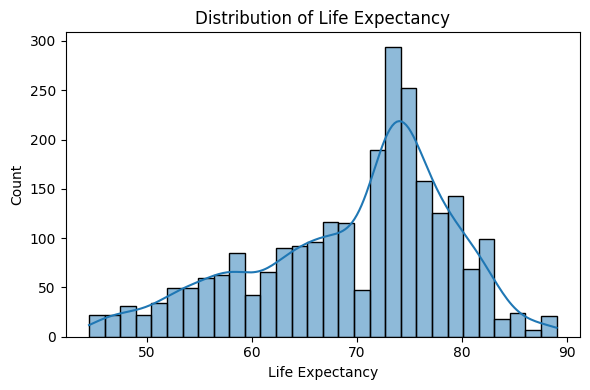

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(df['life_expectancy'], bins=30, kde=True)
plt.xlabel("Life Expectancy")
plt.title("Distribution of Life Expectancy")
plt.tight_layout()
plt.show()

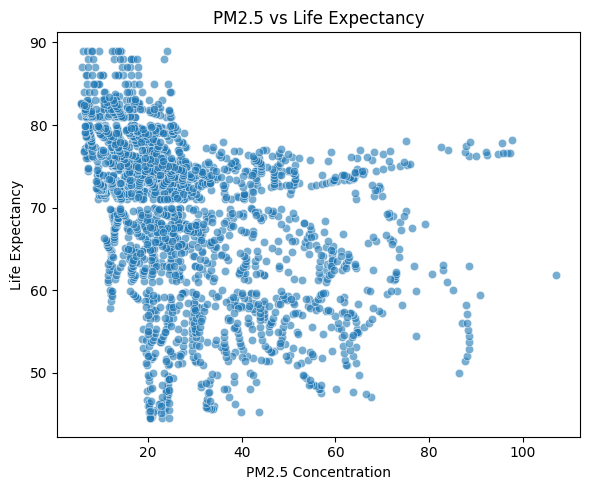

In [ ]:
plt.figure(figsize=(6,5))
sns.scatterplot(
    x=df['pm25'],
    y=df['life_expectancy'],
    alpha=0.6
)
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Life Expectancy")
plt.title("PM2.5 vs Life Expectancy")
plt.tight_layout()
plt.show()


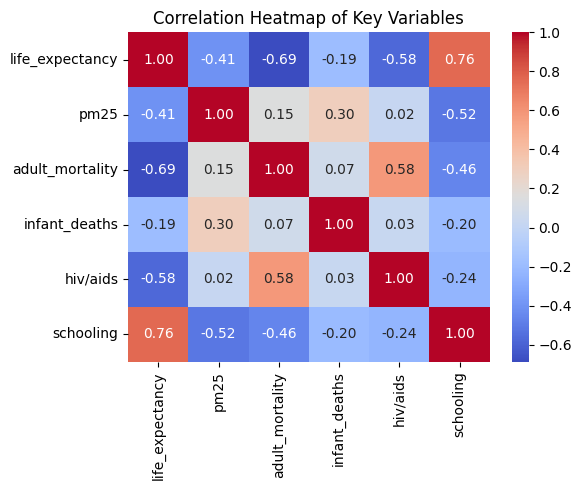

In [ ]:
selected_features = [
    'life_expectancy',
    'pm25',
    'adult_mortality',
    'infant_deaths',
    'hiv/aids',
    'schooling'
]

plt.figure(figsize=(6,5))
sns.heatmap(
    df[selected_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)
plt.title("Correlation Heatmap of Key Variables")
plt.tight_layout()
plt.show()


# 1.Ridge Regression

In [ ]:
path = "/content/drive/MyDrive/final_life_pm25.csv"
df = pd.read_csv(path)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)

y_train_pred_ridge = ridge_model.predict(X_train_scaled)
y_test_pred_ridge = ridge_model.predict(X_test_scaled)

def evaluate_model(y_true, y_pred, dataset_name=""):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"{dataset_name} Results:")
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print("-" * 30)

evaluate_model(y_train, y_train_pred_ridge, "Train")
evaluate_model(y_test, y_test_pred_ridge, "Test")

ridge_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": ridge_model.coef_
}).sort_values(by="Coefficient", ascending=False)

ridge_coefficients


Train Results:
R²   : 0.8202
RMSE : 3.9839
MAE  : 3.0682
------------------------------
Test Results:
R²   : 0.8155
RMSE : 3.9911
MAE  : 2.9868
------------------------------


,Feature,Coefficient
12,schooling,3.896210
8,diphtheria,1.042298
10,gdp,0.887365
1,status,0.665273
7,polio,0.598496
11,population,0.246945
14,country_encoded,0.062954
15,population_log,-0.116082
6,measles,-0.164004
0,year,-0.262964


# 2.Linear Regression

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_train_pred = lr_model.predict(X_train_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)

def evaluate_model(y_true, y_pred, dataset_name=""):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"{dataset_name} Results:")
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print("-" * 30)

evaluate_model(y_train, y_train_pred, "Train")
evaluate_model(y_test, y_test_pred_lr, "Test")

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_model.coef_
}).sort_values(by="Coefficient", ascending=False)

coefficients

# Residuals
residuals = y_test - y_test_pred_lr

print("Mean residual:", residuals.mean())


Train Results:
R²   : 0.8202
RMSE : 3.9839
MAE  : 3.0682
------------------------------
Test Results:
R²   : 0.8155
RMSE : 3.9912
MAE  : 2.9868
------------------------------
Mean residual: 0.2674410593648653


# 3.Decision Tree

In [ ]:
dt_model = DecisionTreeRegressor(
    max_depth=6,          # prevents overfitting
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

y_train_pred = dt_model.predict(X_train)
y_test_pred_dt = dt_model.predict(X_test)

def evaluate_model(y_true, y_pred, dataset_name=""):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"{dataset_name} Results:")
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print("-" * 30)

evaluate_model(y_train, y_train_pred, "Train")
evaluate_model(y_test, y_test_pred_dt, "Test")


Train Results:
R²   : 0.9340
RMSE : 2.4140
MAE  : 1.7384
------------------------------
Test Results:
R²   : 0.9138
RMSE : 2.7279
MAE  : 1.9512
------------------------------


# 4.k-Nearest Neighbors (kNN) Regressor

In [ ]:
# 4. Feature scaling (CRITICAL for kNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Initialize kNN model
knn_model = KNeighborsRegressor(
    n_neighbors=7,        # reasonable default
    weights='distance',   # closer neighbors have more influence
    metric='minkowski'
)

# 6. Train model
knn_model.fit(X_train_scaled, y_train)

# 7. Predictions
y_train_pred_knn = knn_model.predict(X_train_scaled)
y_test_pred_knn = knn_model.predict(X_test_scaled)

# 8. Evaluation
def evaluate_model(y_true, y_pred, name=""):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"{name} Results:")
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print("-" * 35)

evaluate_model(y_train, y_train_pred_knn, "Train")
evaluate_model(y_test, y_test_pred_knn, "Test")

Train Results:
R²   : 1.0000
RMSE : 0.0000
MAE  : 0.0000
-----------------------------------
Test Results:
R²   : 0.8927
RMSE : 3.0439
MAE  : 2.0475
-----------------------------------


# 5.Random Forest

In [ ]:
# 4. Initialize Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,        # number of trees
    max_depth=12,           # controls overfitting
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1               # use all CPU cores
)

# 5. Train model
rf_model.fit(X_train, y_train)

# 6. Predictions
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

# 7. Evaluation
def evaluate_model(y_true, y_pred, name=""):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"{name} Results:")
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print("-" * 35)

evaluate_model(y_train, y_train_pred_rf, "Train")
evaluate_model(y_test, y_test_pred_rf, "Test")


Train Results:
R²   : 0.9873
RMSE : 1.0573
MAE  : 0.6472
-----------------------------------
Test Results:
R²   : 0.9578
RMSE : 1.9092
MAE  : 1.1961
-----------------------------------


# 6.Extra Trees Regressor

In [ ]:
# 4. Initialize Extra Trees model
et_model = ExtraTreesRegressor(
    n_estimators=400,        # more trees = stable
    max_depth=14,           # slightly deeper than RF
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# 5. Train model
et_model.fit(X_train, y_train)

# 6. Predictions
y_train_pred_et = et_model.predict(X_train)
y_test_pred_et = et_model.predict(X_test)

# 7. Evaluation
def evaluate_model(y_true, y_pred, name=""):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"{name} Results:")
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print("-" * 35)

evaluate_model(y_train, y_train_pred_et, "Train")
evaluate_model(y_test, y_test_pred_et, "Test")

Train Results:
R²   : 0.9897
RMSE : 0.9524
MAE  : 0.5939
-----------------------------------
Test Results:
R²   : 0.9621
RMSE : 1.8095
MAE  : 1.1313
-----------------------------------


# 7.Gradient Boosting

In [ ]:
# 4. Initialize Gradient Boosting model
gbr_model = GradientBoostingRegressor(
    n_estimators=300,        # number of boosting stages
    learning_rate=0.05,     # smaller LR for stability
    max_depth=4,            # shallow trees (boosting rule)
    subsample=0.8,          # stochastic boosting
    random_state=42
)

# 5. Train model
gbr_model.fit(X_train, y_train)

# 6. Predictions
y_train_pred_gbr = gbr_model.predict(X_train)
y_test_pred_gbr = gbr_model.predict(X_test)

# 7. Evaluation
def evaluate_model(y_true, y_pred, name=""):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"{name} Results:")
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print("-" * 35)

evaluate_model(y_train, y_train_pred_gbr, "Train")
evaluate_model(y_test, y_test_pred_gbr, "Test")

Train Results:
R²   : 0.9860
RMSE : 1.1097
MAE  : 0.8002
-----------------------------------
Test Results:
R²   : 0.9573
RMSE : 1.9206
MAE  : 1.2573
-----------------------------------


# 8.AdaBoost

In [ ]:
# 4. Base learner (weak learner)
base_estimator = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=5,
    random_state=42
)

# 5. Initialize AdaBoost model
ada_model = AdaBoostRegressor(
    estimator=base_estimator,
    n_estimators=300,
    learning_rate=0.05,
    random_state=42
)

# 6. Train model
ada_model.fit(X_train, y_train)

# 7. Predictions
y_train_pred_ada = ada_model.predict(X_train)
y_test_pred_ada = ada_model.predict(X_test)

# 8. Evaluation
def evaluate_model(y_true, y_pred, name=""):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"{name} Results:")
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print("-" * 35)

evaluate_model(y_train, y_train_pred_ada, "Train")
evaluate_model(y_test, y_test_pred_ada, "Test")

Train Results:
R²   : 0.8921
RMSE : 3.0864
MAE  : 2.4536
-----------------------------------
Test Results:
R²   : 0.8764
RMSE : 3.2668
MAE  : 2.5414
-----------------------------------


# 9.XGBoost

In [ ]:
!pip install xgboost --upgrade


In [ ]:
# 4. Initialize XGBoost model (GPU enabled)
xgb_model = xgb.XGBRegressor(
    tree_method='hist',
    device='cuda',        # NEW way
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42
)

# 5. Train model
xgb_model.fit(X_train, y_train)

# 6. Predictions
y_train_pred_xgb = xgb_model.predict(X_train)
y_test_pred_xgb = xgb_model.predict(X_test)

# 7. Evaluation
def evaluate_model(y_true, y_pred, name=""):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"{name} Results:")
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print("-" * 35)

evaluate_model(y_train, y_train_pred_xgb, "Train")
evaluate_model(y_test, y_test_pred_xgb, "Test")

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [05:02:58] WARNING: /workspace/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [05:02:58] WARNING: /workspace/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


Train Results:
R²   : 0.9993
RMSE : 0.2497
MAE  : 0.1759
-----------------------------------
Test Results:
R²   : 0.9629
RMSE : 1.7899
MAE  : 1.0719
-----------------------------------


# 10.MLP Regressor

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Initialize MLP model
mlp_model = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    alpha=0.0005,          # L2 regularization
    learning_rate='adaptive',
    max_iter=800,
    random_state=42
)

# 6. Train model
mlp_model.fit(X_train_scaled, y_train)

# 7. Predictions
y_train_pred_mlp = mlp_model.predict(X_train_scaled)
y_test_pred_mlp = mlp_model.predict(X_test_scaled)

# 8. Evaluation
evaluate_model(y_train, y_train_pred_mlp, "Train")
evaluate_model(y_test, y_test_pred_mlp, "Test")


Train Results:
R²   : 0.9719
RMSE : 1.5762
MAE  : 1.0979
-----------------------------------
Test Results:
R²   : 0.8863
RMSE : 3.1333
MAE  : 2.0043
-----------------------------------


# Training Results

In [ ]:
# RESULTS & EVALUATION: Master Comparison Table

results = []

def add_result(model_name, y_true, y_pred):
    results.append({
        "Model": model_name,
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred)
    })

add_result("Linear Regression", y_test, y_test_pred_lr)
add_result("Ridge Regression", y_test, y_test_pred_ridge)
add_result("Decision Tree", y_test, y_test_pred_dt)
add_result("kNN", y_test, y_test_pred_knn)
add_result("Random Forest", y_test, y_test_pred_rf)
add_result("Extra Trees", y_test, y_test_pred_et)
add_result("Gradient Boosting", y_test, y_test_pred_gbr)
add_result("AdaBoost", y_test, y_test_pred_ada)
add_result("XGBoost", y_test, y_test_pred_xgb)
add_result("MLP Regressor", y_test, y_test_pred_mlp)

results_df = pd.DataFrame(results).sort_values(by="R2", ascending=False)
results_df


,Model,R2,RMSE,MAE
8,XGBoost,0.962900,1.789938,1.071920
5,Extra Trees,0.962085,1.809487,1.131253
4,Random Forest,0.957792,1.909186,1.196094
6,Gradient Boosting,0.957284,1.920644,1.257284
2,Decision Tree,0.913829,2.727907,1.951212
3,kNN,0.892711,3.043878,2.047470
9,MLP Regressor,0.886315,3.133299,2.004301
7,AdaBoost,0.876420,3.266808,2.541377
1,Ridge Regression,0.815547,3.991097,2.986767
0,Linear Regression,0.815542,3.991156,2.986802


In [ ]:
results_df.to_csv("model_comparison_results.csv", index=False)


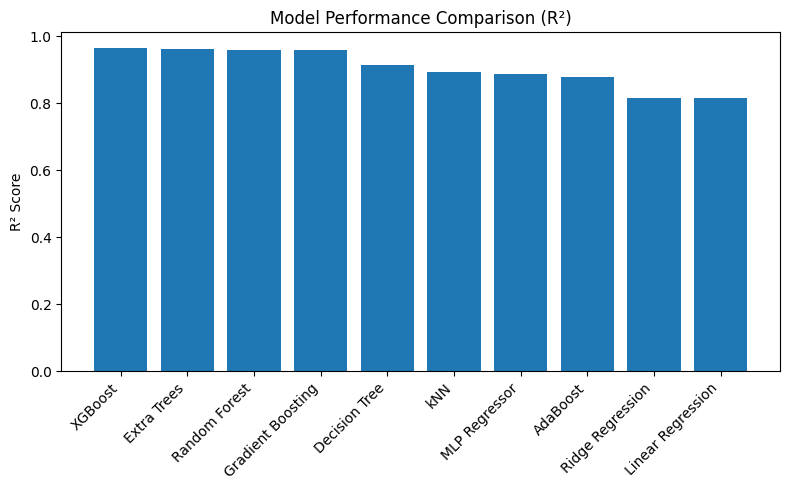

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["R2"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("R² Score")
plt.title("Model Performance Comparison (R²)")
plt.tight_layout()
plt.savefig("r2_comparison.png", dpi=300)
plt.show()

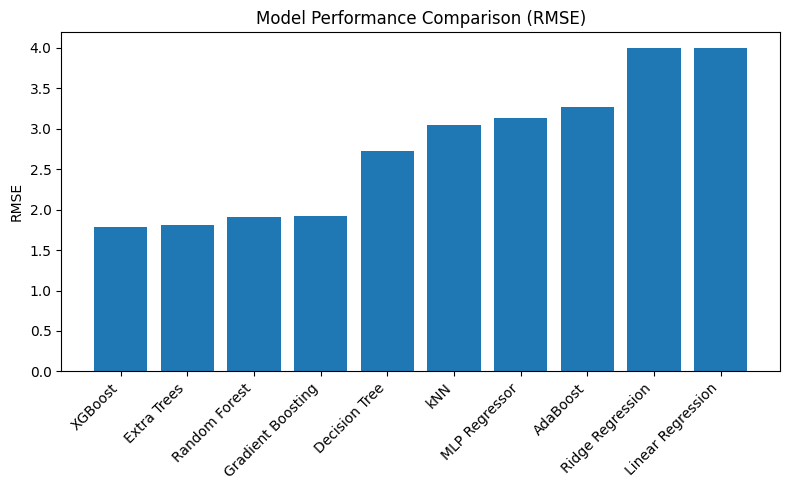

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("RMSE")
plt.title("Model Performance Comparison (RMSE)")
plt.tight_layout()
plt.savefig("rmse_comparison.png", dpi=300)
plt.show()


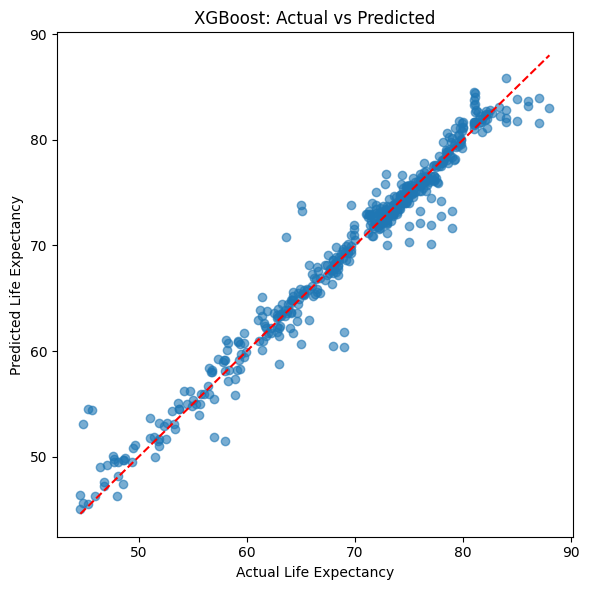

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_test_pred_xgb, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("XGBoost: Actual vs Predicted")
plt.tight_layout()
plt.savefig("xgb_actual_vs_predicted.png", dpi=300)
plt.show()
